In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
import torchvision.datasets as datasets

from src.data import (
    PKBatchSampler,
    build_identity_index_map,
    get_eval_transforms,
    get_train_transforms,
)
from src.losses import TripletMarginLoss
from src.models import FaceEmbeddingNet
from src.trainer import MetricTrainer


def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(42)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")

# Project-relative paths (adjust if your notebook sits inside a notebooks/ subfolder)
DATA_ROOT = Path("data/for_students/faces")
TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR = DATA_ROOT / "val"
CHECKPOINT_DIR = Path("checkpoints/resnet18_triplet")

Using device: mps


In [2]:
IMAGE_SIZE = (128, 128)
P = 16  # Distinct identities per batch
K = 4   # Images per identity per batch -> batch size = 64

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=get_train_transforms(IMAGE_SIZE),
)
val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=get_eval_transforms(IMAGE_SIZE),
)

identity_to_indices = build_identity_index_map(train_dataset)
train_sampler = PKBatchSampler(
    identity_to_indices=identity_to_indices,
    p=P,
    k=K,
    batches_per_epoch=max(1, len(identity_to_indices) // P),
    seed=42,
)

# pin_memory is only supported on CUDA; num_workers=0 avoids macOS notebook fork issues
use_pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_sampler=train_sampler,
    num_workers=0,
    pin_memory=use_pin_memory,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin_memory,
)

print(
    f"Train: {len(train_dataset)} images across {len(identity_to_indices)} identities "
    f"({len(train_sampler)} batches/epoch of size {P * K})"
)
print(f"Val:   {len(val_dataset)} images across {len(val_dataset.classes)} identities")


Train: 3399 images across 292 identities (18 batches/epoch of size 64)
Val:   758 images across 62 identities


In [3]:
MARGIN = 0.2
EPOCHS = 40

model = FaceEmbeddingNet(
    backbone="resnet18",
    embedding_dim=128,
    pretrained=True,
    freeze_backbone=False,
)

criterion = TripletMarginLoss(margin=MARGIN, reduction="mean")

trainer = MetricTrainer(
    model=model,
    criterion=criterion,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    margin=MARGIN,
    backbone_lr=1e-5,        # Gentle LR to preserve pretrained facial features
    head_lr=5e-4,            # Higher LR for the newly initialized projection head
    weight_decay=1e-4,
    epochs=EPOCHS,
    val_num_pairs=1000,
    val_seed=42,
    mining_fallback="hardest",
    checkpoint_dir=CHECKPOINT_DIR,
    monitor="eer",           # Saves best_model.pt whenever validation EER improves
)

In [4]:
# Interrupting the cell (Stop button / KeyboardInterrupt) safely stops training
# and automatically reloads the best checkpoint saved so far.
history = trainer.fit()

# To resume a previously interrupted run from the last saved epoch instead:
# history = trainer.fit(resume_from=CHECKPOINT_DIR / "last_checkpoint.pt")

print(f"\nBest Epoch: {trainer.best_epoch} | Best Val EER: {trainer.best_score:.2%}")

Training:   0%|          | 0/18 [00:00<?, ?it/s]

Epoch [01/40] Loss: 0.1715 | Active Triplets: 96.5% | Val Acc: 73.40% | Val AUC: 0.7982 | EER: 27.80% | Margin (Neg-Pos): 0.388  <-- BEST


Training:   0%|          | 0/18 [00:00<?, ?it/s]

Epoch [02/40] Loss: 0.1524 | Active Triplets: 92.0% | Val Acc: 76.10% | Val AUC: 0.8279 | EER: 25.30% | Margin (Neg-Pos): 0.447  <-- BEST


Training:   0%|          | 0/18 [00:00<?, ?it/s]

Epoch [03/40] Loss: 0.1468 | Active Triplets: 90.4% | Val Acc: 77.00% | Val AUC: 0.8479 | EER: 24.00% | Margin (Neg-Pos): 0.511  <-- BEST


... (70 outputs left out)

Training:   0%|          | 0/18 [00:00<?, ?it/s]

Epoch [39/40] Loss: 0.0650 | Active Triplets: 50.5% | Val Acc: 82.90% | Val AUC: 0.8995 | EER: 18.00% | Margin (Neg-Pos): 0.690


Training:   0%|          | 0/18 [00:00<?, ?it/s]

Epoch [40/40] Loss: 0.0643 | Active Triplets: 48.3% | Val Acc: 83.20% | Val AUC: 0.9005 | EER: 17.40% | Margin (Neg-Pos): 0.689
Loaded best weights from epoch 21 (checkpoints/resnet18_triplet/best_model.pt).

Best Epoch: 21 | Best Val EER: 16.60%


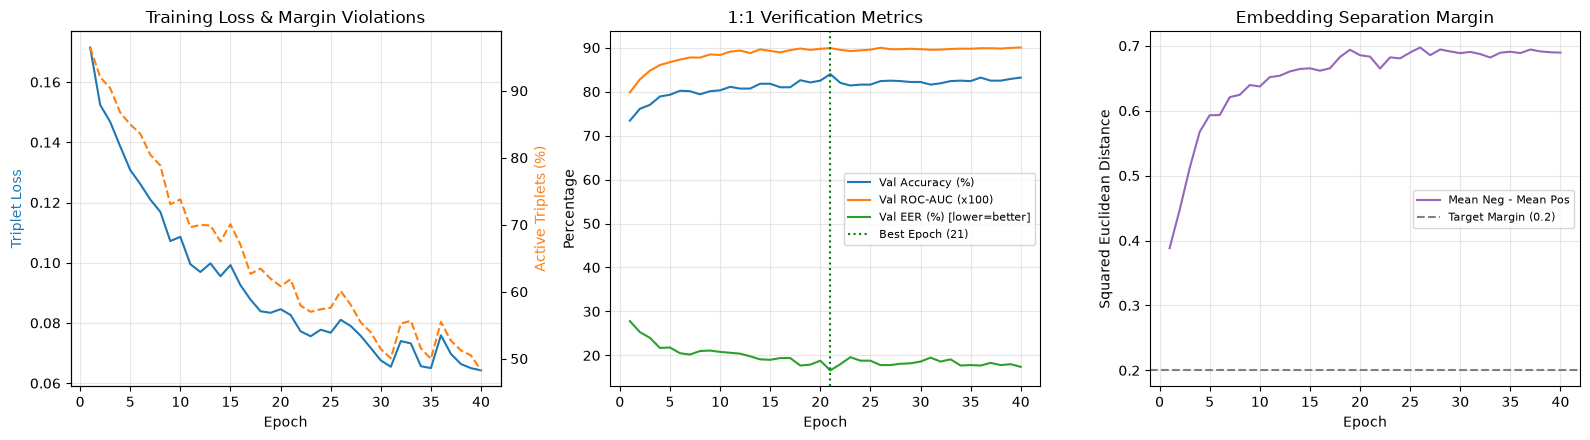

In [5]:
epochs = [s.epoch for s in history]
train_losses = [s.train_loss for s in history]
active_ratios = [s.active_triplets_ratio * 100 for s in history]
val_aucs = [s.val_auc for s in history]
val_accs = [s.val_accuracy * 100 for s in history]
val_eers = [s.val_eer * 100 for s in history]
val_margins = [s.val_margin for s in history]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Training Loss & Active Triplets (%)
ax1 = axes[0]
ax1.plot(epochs, train_losses, color="tab:blue", label="Train Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Triplet Loss", color="tab:blue")
ax1.grid(True, alpha=0.3)

ax1_twin = ax1.twinx()
ax1_twin.plot(epochs, active_ratios, color="tab:orange", linestyle="--", label="Active Triplets (%)")
ax1_twin.set_ylabel("Active Triplets (%)", color="tab:orange")
ax1.set_title("Training Loss & Margin Violations")

# 2. Validation ROC-AUC, Accuracy & EER
ax2 = axes[1]
ax2.plot(epochs, val_accs, label="Val Accuracy (%)")
ax2.plot(epochs, [a * 100 for a in val_aucs], label="Val ROC-AUC (x100)")
ax2.plot(epochs, val_eers, label="Val EER (%) [lower=better]")
if trainer.best_epoch is not None:
    ax2.axvline(trainer.best_epoch, color="green", linestyle=":", label=f"Best Epoch ({trainer.best_epoch})")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Percentage")
ax2.set_title("1:1 Verification Metrics")
ax2.legend(loc="best", fontsize=8)
ax2.grid(True, alpha=0.3)

# 3. Inter-Class vs. Intra-Class Distance Gap (Neg - Pos)
ax3 = axes[2]
ax3.plot(epochs, val_margins, color="tab:purple", label="Mean Neg - Mean Pos")
ax3.axhline(MARGIN, color="gray", linestyle="--", label=f"Target Margin ({MARGIN})")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Squared Euclidean Distance")
ax3.set_title("Embedding Separation Margin")
ax3.legend(loc="best", fontsize=8)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Saved comparison figure to: /Users/adendek/Documents/PythonProjects/deepgate-facerec/notebooks/reports/figures/val_embeddings_tsne_comparison.png
Cosine Silhouette Score: -0.011 (Before) -> +0.111 (After)


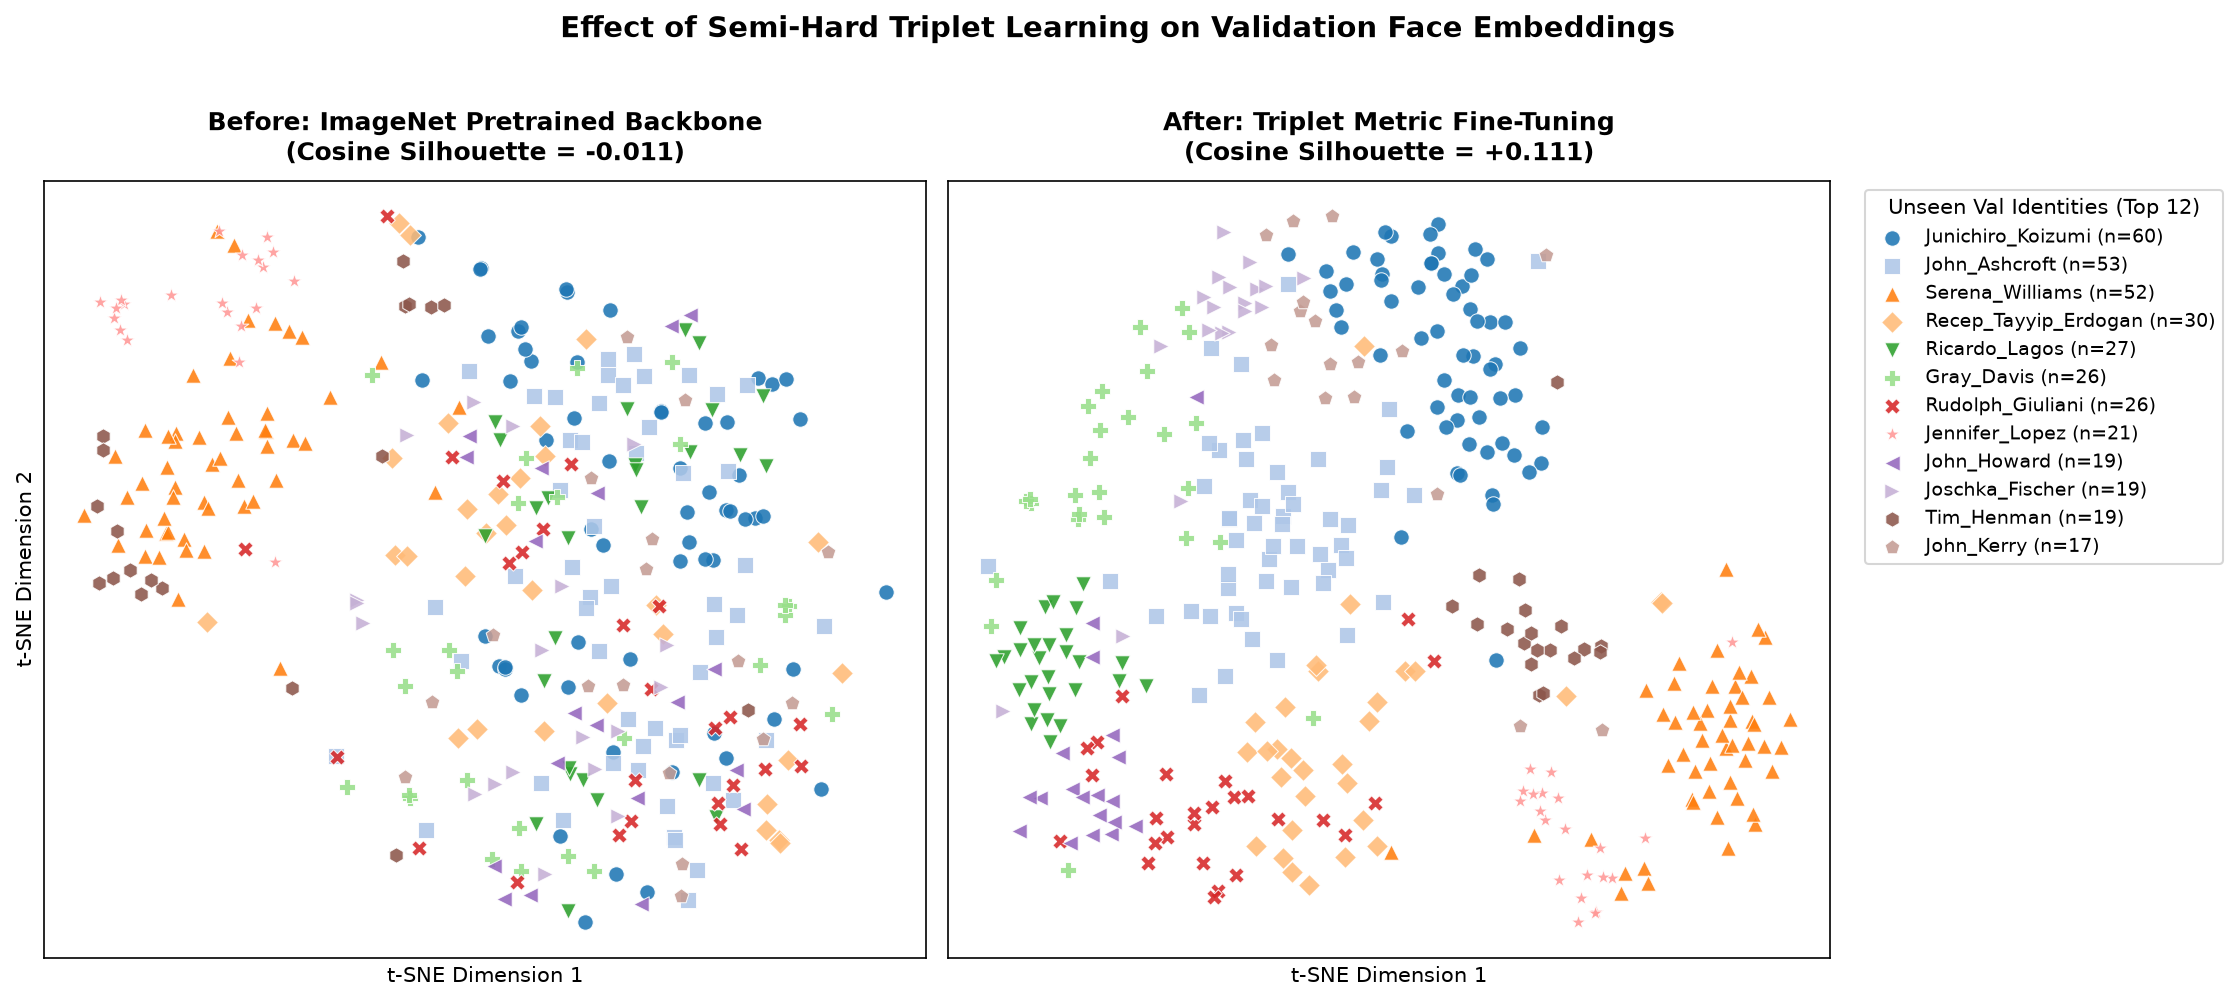

In [6]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import torch

from src.models import FaceEmbeddingNet


@torch.inference_mode()
def extract_embeddings(
    net: torch.nn.Module,
    loader: torch.utils.data.DataLoader,
    compute_device: torch.device,
) -> tuple[np.ndarray, np.ndarray]:
    net.eval()
    embs: list[torch.Tensor] = []
    lbls: list[torch.Tensor] = []
    for images, labels in loader:
        images = images.to(compute_device, non_blocking=True)
        embs.append(net(images).cpu())
        lbls.append(labels.cpu())
    return torch.cat(embs, dim=0).numpy(), torch.cat(lbls, dim=0).numpy()


# 1. Extract embeddings from the fine-tuned triplet model
trained_embs, labels_np = extract_embeddings(model, val_loader, device)
embedding_dim = trained_embs.shape[1]

# 2. Extract embeddings from an untrained baseline (ImageNet backbone + random projection head)
torch.manual_seed(42)
baseline_model = FaceEmbeddingNet(
    backbone="resnet18",
    embedding_dim=embedding_dim,
    pretrained=True,
    freeze_backbone=False,
).to(device)
baseline_embs, _ = extract_embeddings(baseline_model, val_loader, device)

# 3. Filter both sets to the exact same top-N unseen validation identities
TOP_N_IDENTITIES = 12
label_counts = Counter(labels_np.tolist())
top_identities = [lbl for lbl, _ in label_counts.most_common(TOP_N_IDENTITIES)]
mask = np.isin(labels_np, top_identities)

sub_baseline = baseline_embs[mask]
sub_trained = trained_embs[mask]
sub_labels = labels_np[mask]

# 4. Quantify cluster compactness & separation using Cosine Silhouette Score in [-1, 1]
sil_baseline = float(silhouette_score(sub_baseline, sub_labels, metric="cosine"))
sil_trained = float(silhouette_score(sub_trained, sub_labels, metric="cosine"))

# 5. Project both 128-D embedding spaces to 2-D via t-SNE
perplexity = min(30, max(5, (len(sub_labels) - 1) // 3))
tsne_params = dict(
    n_components=2,
    metric="cosine",
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=42,
)
coords_baseline = TSNE(**tsne_params).fit_transform(sub_baseline)
coords_trained = TSNE(**tsne_params).fit_transform(sub_trained)

# 6. Plot 1x2 side-by-side comparison figure with a shared legend
class_names = getattr(val_dataset, "classes", None)
cmap = plt.get_cmap("tab20")
markers = ("o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "p")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), dpi=150)

panels = [
    (
        axes[0],
        coords_baseline,
        f"Before: ImageNet Pretrained Backbone\n(Cosine Silhouette = {sil_baseline:+.3f})",
    ),
    (
        axes[1],
        coords_trained,
        f"After: Triplet Metric Fine-Tuning\n(Cosine Silhouette = {sil_trained:+.3f})",
    ),
]

for panel_idx, (ax, coords, title) in enumerate(panels):
    for idx, identity_id in enumerate(top_identities):
        pts = coords[sub_labels == identity_id]
        display_name = (
            class_names[identity_id]
            if class_names is not None and identity_id < len(class_names)
            else f"Identity {identity_id}"
        )
        ax.scatter(
            pts[:, 0],
            pts[:, 1],
            label=f"{display_name} (n={len(pts)})" if panel_idx == 1 else None,
            color=cmap(idx % 20),
            marker=markers[idx % len(markers)],
            s=55,
            alpha=0.88,
            edgecolors="white",
            linewidths=0.5,
        )

    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("t-SNE Dimension 1", fontsize=10)
    if panel_idx == 0:
        ax.set_ylabel("t-SNE Dimension 2", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(True, linestyle="--", alpha=0.25)

axes[1].legend(
    title=f"Unseen Val Identities (Top {len(top_identities)})",
    bbox_to_anchor=(1.03, 1.0),
    loc="upper left",
    frameon=True,
    fontsize=9,
    title_fontsize=10,
)

fig.suptitle(
    "Effect of Semi-Hard Triplet Learning on Validation Face Embeddings",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

fig_dir = Path("reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
fig_path = fig_dir / "val_embeddings_tsne_comparison.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved comparison figure to: {fig_path.resolve()}")
print(f"Cosine Silhouette Score: {sil_baseline:+.3f} (Before) -> {sil_trained:+.3f} (After)")

plt.show()